In [1]:
#dependencias
import pandas as pd
import json
import pyarrow.parquet as pq

In [2]:
#cargar el dataset parquet
tabla = pq.read_table('../data_sample/subset_dataset.parquet')
df = tabla.to_pandas()

In [3]:
#convertir la columna Timestamp a tipo datetime
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"], 
    format="%d/%m/%Y %H:%M:%S",   # día/mes/año
    errors="coerce"
)
#ordenar respecto al tiempo
df = df.sort_values("Timestamp")

In [4]:
import pandas as pd

rows = []
for (src_ip, dst_ip), group in df.groupby(["Source IP", "Destination IP"]):
    # Ordenar cada grupo por tiempo
    group = group.sort_values("Timestamp")
    
    # Seleccionar columnas relevantes como observables
    for _, row in group.iterrows():
        rows.append({
            "Source IP": src_ip,
            "Destination IP": dst_ip,
            "Protocol": row["Protocol"],
            "Flow Duration": row["Flow Duration"],
            "Total Fwd Packets": row["Total Fwd Packets"],
            "Total Backward Packets": row["Total Backward Packets"],
            "Flow Bytes/s": row["Flow Bytes/s"],
            "Timestamp": row["Timestamp"]  # opcional, útil para ordenar/analizar
        })

# Convertir a DataFrame
df = pd.DataFrame(rows)


### **Ranking de eventos por par de IPs**

#### Hago un resumen estadístico para saber cuáles pares de IPs son los mas activos en cuanto a cantidad de eventos. 

In [5]:
#guardo las secuencias (pares de IP) con más eventos
active_pairs = df.groupby(["Source IP", "Destination IP"]).size().sort_values(ascending=False).head(20)

In [6]:
active_pairs

Source IP       Destination IP
172.16.0.1      192.168.10.50     13147
192.168.10.3    192.168.10.1      10078
192.168.10.50   172.16.0.1         3293
192.168.10.9    192.168.10.3       2781
192.168.10.12   192.168.10.3       2776
192.168.10.5    192.168.10.3       2759
192.168.10.15   192.168.10.3       2629
192.168.10.14   192.168.10.3       2358
192.168.10.8    192.168.10.3       2054
192.168.10.17   192.168.10.3       1817
192.168.10.16   192.168.10.3       1734
192.168.10.19   192.168.10.3       1639
192.168.10.25   192.168.10.3       1032
192.168.10.51   192.168.10.3        984
192.168.10.50   192.168.10.3        504
35.186.227.40   192.168.10.25       325
192.168.10.25   35.186.227.40       249
192.168.10.5    162.208.20.178      186
192.168.10.51   162.213.33.44       176
162.208.20.178  192.168.10.5        154
dtype: int64

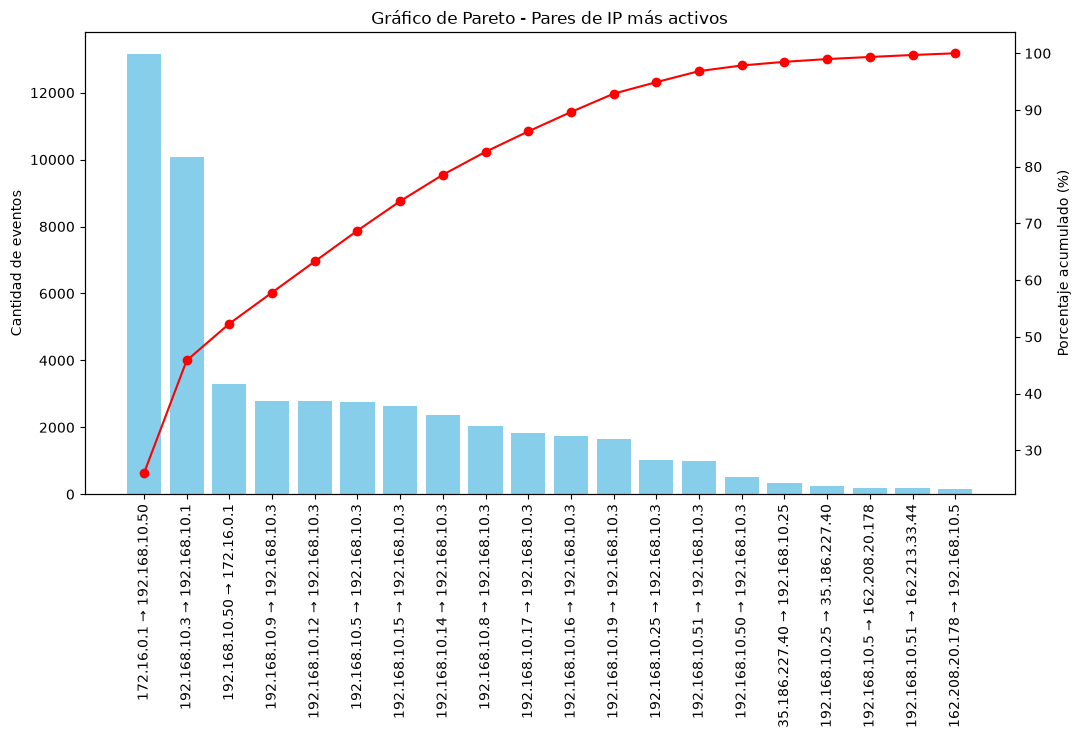

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Convertir active_pairs a DataFrame
active_pairs_df = active_pairs.reset_index()
active_pairs_df.columns = ["Source IP", "Destination IP", "Count"]

# Ordenar de mayor a menor
active_pairs_df = active_pairs_df.sort_values("Count", ascending=False)

# Calcular porcentaje acumulado
active_pairs_df["CumPerc"] = active_pairs_df["Count"].cumsum() / active_pairs_df["Count"].sum() * 100

# Gráfico Pareto
fig, ax1 = plt.subplots(figsize=(12,6))

# Barras (cantidad de eventos)
ax1.bar(
    active_pairs_df["Source IP"] + " → " + active_pairs_df["Destination IP"],
    active_pairs_df["Count"],
    color="skyblue"
)
ax1.set_ylabel("Cantidad de eventos")
ax1.tick_params(axis="x", rotation=90)

# Línea acumulada (porcentaje)
ax2 = ax1.twinx()
ax2.plot(
    active_pairs_df["Source IP"] + " → " + active_pairs_df["Destination IP"],
    active_pairs_df["CumPerc"],
    color="red",
    marker="o"
)
ax2.set_ylabel("Porcentaje acumulado (%)")

plt.title("Gráfico de Pareto - Pares de IP más activos")
plt.show()


## Interpretación
Las **barras azules** muestran cuántos eventos tiene cada par de IP.

La **línea roja** muestra el porcentaje acumulado del tráfico total explicado por esos pares.  

Por eso, aunque las barras bajen (menos eventos por par), la línea sigue subiendo — cada par adicional aumenta el porcentaje acumulado, aunque sea poco.

- Los **primeros 2 pares** explican casi el **40–50 % del tráfico total**.  
- Los **primeros 10 pares** probablemente cubren más del **90 % del tráfico**.  
- El resto aporta muy poco, lo que confirma el principio de Pareto: **pocos pares concentran la mayoría del tráfico**.

## Pasar de ese resumen a las secuencias de observables

#### Primeramente hago un **resumen estadístico del df** para diagnosticar la escala de las variabes usando **``df.describe()``**. 

In [8]:
df.describe()

c:\Users\usr\Documents\LCD\Investigación operativa 2\HMM-Ciberseguridad\.venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Bytes/s,Timestamp
count,92539.000000,9.253900e+04,92539.000000,92539.000000,9.253000e+04,52992
mean,10.038157,1.209493e+07,8.671371,9.448308,inf,2017-07-03 07:38:26.970127
min,0.000000,-1.000000e+00,1.000000,0.000000,-2.610000e+08,2017-07-03 01:00:08
25%,6.000000,2.140000e+02,2.000000,1.000000,1.145034e+02,2017-07-03 03:29:59
50%,6.000000,6.053000e+04,2.000000,2.000000,4.922378e+03,2017-07-03 09:41:47.500000
75%,17.000000,3.984063e+06,5.000000,5.000000,1.538462e+05,2017-07-03 11:09:01
max,17.000000,1.199999e+08,193200.000000,256740.000000,inf,2017-07-03 12:59:55
std,5.307809,3.002341e+07,647.899911,862.292926,NaN,NaN


### Aplico una normalización. 

### Descarto la variable ``Timestamp`` porque no es una variable observable necesaria para el modelo

#### Análisis de cada variable

- **Protocol**
  - Valores entre 0 y 17, con media ≈ 10.
  - Es una variable **categórica discreta** (representa protocolos de red: TCP=6, UDP=17, etc.).
  - No necesita normalización numérica; lo correcto es **codificarla**:
    - Si tu HMM es **discreto**, podés dejarla como entero.
    - Si tu HMM es **gaussiano/continuo**, conviene hacer **one-hot encoding**.

- **Flow Duration**
  - Rango enorme: desde -1 (error en el dataset) hasta 1.2×10⁸.
  - Mediana ≈ 6×10⁴, pero con colas largas (percentil 75 ≈ 4×10⁶).
  - Necesita limpieza: reemplazar negativos por 0.
  - Transformación recomendada: **log1p** para comprimir la escala, luego **StandardScaler** o **RobustScaler**.

- **Total Fwd Packets / Total Backward Packets**
  - La mayoría de los valores son muy bajos (mediana ≈ 2), pero hay outliers enormes (hasta 193k y 256k).
  - Distribución muy sesgada.
  - Recomendación: aplicar **log1p** para suavizar colas largas y después escalar.
  - Alternativa: usar **RobustScaler** (basado en mediana/IQR) para que los outliers no dominen.

- **Flow Bytes/s**
  - Problema serio: aparecen valores **inf** y negativos (!).
  - Esto viene de divisiones por cero o errores en el dataset.
  - Pasos necesarios:
    1. Reemplazar `inf` y `NaN` con valores manejables (`np.nan_to_num`).
    2. Filtrar o corregir negativos (ponerlos en 0).
    3. Aplicar **log1p** para comprimir la escala.
    4. Escalar con `StandardScaler` o `RobustScaler`.

- **Timestamp**
  - No es una variable observable para el HMM, solo sirve para ordenar.
  - Podés descartarla del entrenamiento.
<!-- 
### 🎯 Conclusión

- **Protocol** → codificar (entero o one-hot).  
- **Flow Duration, Packets, Bytes/s** → limpiar (inf/NaN/negativos), aplicar `log1p`, luego escalar.  
- **Timestamp** → solo para ordenar, no entra al modelo.  -->

In [9]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, RobustScaler

#copia de las columnas numéricas
num_cols = ["Flow Duration","Total Fwd Packets","Total Backward Packets","Flow Bytes/s"]
X = df[num_cols].copy()

#reemplazar inf/NaN y negativos en Flow Bytes/s
X["Flow Bytes/s"] = np.nan_to_num(X["Flow Bytes/s"], nan=0.0, posinf=1e9, neginf=0.0)
X["Flow Bytes/s"] = X["Flow Bytes/s"].clip(lower=0)

#reemplazar negativos en Flow Duration
X["Flow Duration"] = X["Flow Duration"].clip(lower=0)

#transformación log1p
X_log = np.log1p(X)

#escalado (podés elegir StandardScaler o RobustScaler)
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_log)

#dataFrame final normalizado
df_scaled = pd.DataFrame(X_scaled, columns=num_cols, index=df.index)

# Protocol: codificación
df_scaled["Protocol"] = df["Protocol"].astype(int)  # o one-hot si tu HMM lo requiere

In [10]:
#hago un resumen estadístico de las variables transformadas
df_scaled.describe()

,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Bytes/s,Protocol
count,92539.000000,92539.000000,92539.000000,92539.000000,92539.000000
mean,-0.038398,0.490033,0.078409,-0.062542,10.038157
std,0.514579,1.094560,0.832601,0.650810,5.307809
min,-1.120455,-0.584963,-1.000000,-1.181650,0.000000
25%,-0.573947,0.000000,-0.369070,-0.521575,6.000000
50%,0.000000,0.000000,0.000000,0.000000,6.000000
75%,0.426053,1.000000,0.630930,0.478425,17.000000
max,0.772561,15.974781,10.337779,1.799898,17.000000


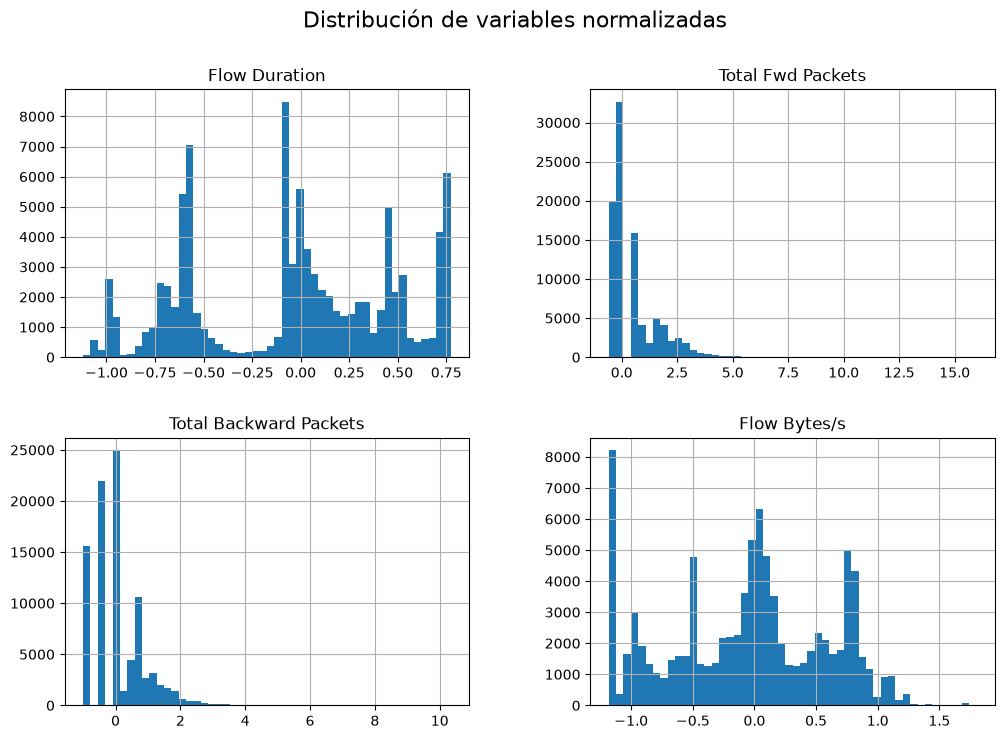

In [11]:
import matplotlib.pyplot as plt

df_scaled[["Flow Duration","Total Fwd Packets","Total Backward Packets","Flow Bytes/s"]].hist(
    bins=50, figsize=(12,8)
)
plt.suptitle("Distribución de variables normalizadas", fontsize=16)
plt.show()


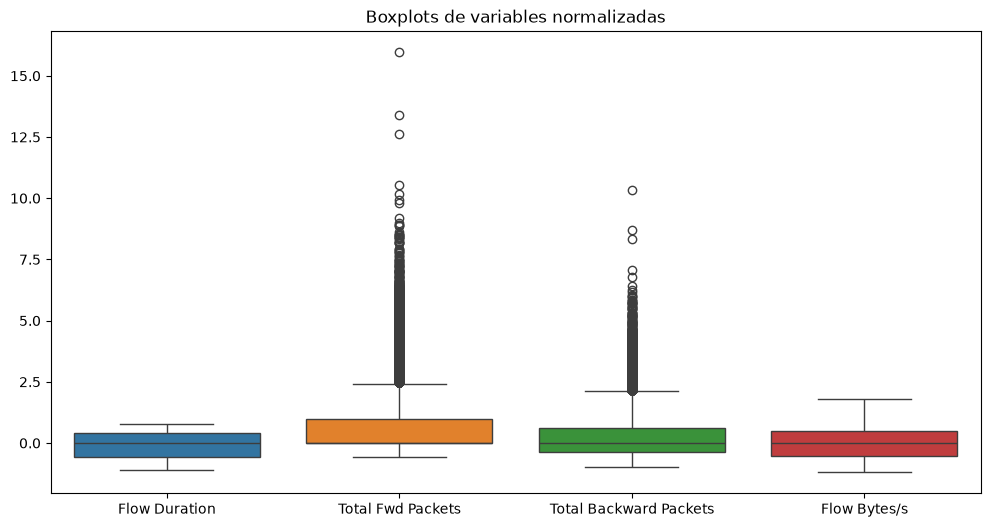

In [14]:
import seaborn as sns

plt.figure(figsize=(12,6))
sns.boxplot(data=df_scaled[["Flow Duration","Total Fwd Packets","Total Backward Packets","Flow Bytes/s"]])
plt.title("Boxplots de variables normalizadas")
plt.show()


In [12]:
# with open("sequences.json", "w") as f:
#     json.dump(sequences, f)